In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

import gausspy.gp as gp

from spectra_utils import load_spectra_from_df

In [2]:
base_dir = Path(r"/Users/javier/FLAMES_30Dor")
data_folder = "ADP_FLAMES_30Dor_30arcmin"
fits_dir = base_dir / data_folder

base_dir_test = Path(r"/Users/javier/FLAMES_30Dor/gausspyp_v02.2")

In [3]:


pickle_path = base_dir / "df-flames-grid-r150arcsec.pkl"
out_dir = base_dir_test / "gausspy_validation"
out_dir.mkdir(exist_ok=True)

print("Base directory:", base_dir)
print("FITS directory:", fits_dir)
print("Metadata pickle:", pickle_path)
print("Output directory:", out_dir)


Base directory: /Users/javier/FLAMES_30Dor
FITS directory: /Users/javier/FLAMES_30Dor/ADP_FLAMES_30Dor_30arcmin
Metadata pickle: /Users/javier/FLAMES_30Dor/df-flames-grid-r150arcsec.pkl
Output directory: /Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation


In [4]:
import pandas as pd
from pathlib import Path

df_flames = pd.read_csv('df-flames-grid.csv')

print(type(df_flames))
print(df_flames.columns)
print(df_flames.head())

<class 'pandas.core.frame.DataFrame'>
Index(['filename', 'object', 'date_obs', 'mjd_obs', 'instrument', 'telescope',
       'arcfile', 'prog_id', 'pro_catg', 'dpr_catg', 'dpr_type', 'dpr_tech',
       'ra_deg', 'dec_deg', 'EXPTIME', 'EXPTIME_round', 'sample_id',
       'object_group', 'sample', 'ra_hms', 'dec_dms'],
      dtype='object')
                           filename  object                 date_obs  \
0  ADP.2019-01-31T23_53_42.052.fits  pos078  2003-12-03T08:13:17.621   
1  ADP.2019-01-31T23_53_42.083.fits  pos011  2003-12-03T08:13:17.621   
2  ADP.2019-01-31T23_53_42.122.fits  pos069  2003-12-03T08:13:17.621   
3  ADP.2019-01-31T23_53_42.163.fits  pos037  2003-12-03T08:13:17.621   
4  ADP.2019-01-31T23_53_42.236.fits  pos093  2003-12-03T08:13:17.621   

        mjd_obs instrument   telescope                           arcfile  \
0  52976.342565    GIRAFFE  ESO-VLT-U2  ADP.2019-01-31T23:53:42.052.fits   
1  52976.342565    GIRAFFE  ESO-VLT-U2  ADP.2019-01-31T23:53:42.083.fits   

In [5]:
for key, df in df_flames.items():
    print(key, df.shape)

filename (1382,)
object (1382,)
date_obs (1382,)
mjd_obs (1382,)
instrument (1382,)
telescope (1382,)
arcfile (1382,)
prog_id (1382,)
pro_catg (1382,)
dpr_catg (1382,)
dpr_type (1382,)
dpr_tech (1382,)
ra_deg (1382,)
dec_deg (1382,)
EXPTIME (1382,)
EXPTIME_round (1382,)
sample_id (1382,)
object_group (1382,)
sample (1382,)
ra_hms (1382,)
dec_dms (1382,)


Load spectra samples using spectra_utils

In [6]:
spectra_validation = load_spectra_from_df(df_flames, fits_dir)

Loaded 1382 spectra


spectra_dict = {}

for name, df in df_flames.items():
    print(f"\nLoading spectra for group {name}")
    spectra_dict[name] = load_spectra_from_df(df_flames, fits_dir)

In [7]:
spectra_dict = {}

for sample_name, df_group in df_flames.groupby("sample"):
    print(f"\nLoading spectra for group {sample_name}")
    spectra_dict[sample_name] = load_spectra_from_df(df_group, fits_dir)

print(spectra_dict.keys())


Loading spectra for group irr
Loaded 112 spectra

Loading spectra for group letterW
Loaded 101 spectra

Loading spectra for group letterX
Loaded 98 spectra

Loading spectra for group letterY
Loaded 71 spectra

Loading spectra for group stellarA
Loaded 111 spectra

Loading spectra for group stellarB
Loaded 112 spectra

Loading spectra for group stellarD
Loaded 220 spectra

Loading spectra for group stellarE
Loaded 109 spectra

Loading spectra for group stellarG
Loaded 111 spectra

Loading spectra for group stellarI
Loaded 113 spectra

Loading spectra for group stellarJ
Loaded 113 spectra

Loading spectra for group stellarK
Loaded 111 spectra
dict_keys(['irr', 'letterW', 'letterX', 'letterY', 'stellarA', 'stellarB', 'stellarD', 'stellarE', 'stellarG', 'stellarI', 'stellarJ', 'stellarK'])


Index: 16


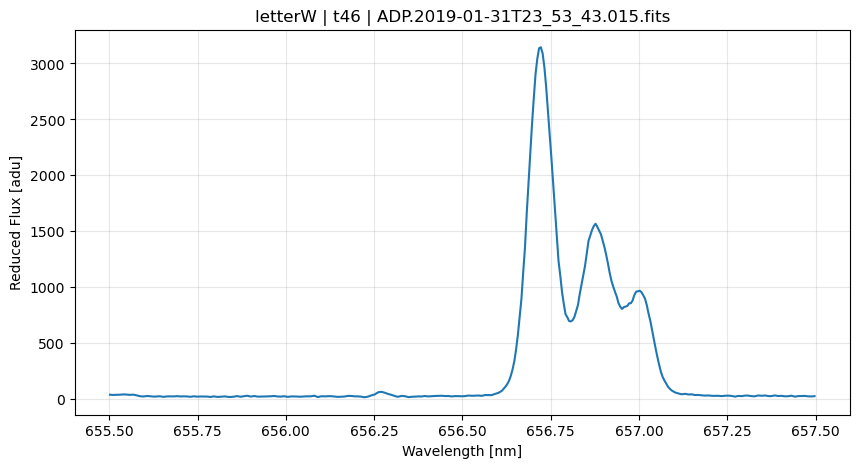

In [8]:
sample = "letterW"
name_object = "t46"

wmin = 655.5
wmax = 657.5

idx = next((i for i, d in enumerate(spectra_dict[sample]) if d["object"] == name_object), None)
print("Index:", idx)

if idx is not None:
    spec = spectra_dict[sample][idx]
    mask = (spec["wave"] >= wmin) & (spec["wave"] <= wmax)

    plt.figure(figsize=(10, 5))
    plt.plot(spec["wave"][mask], spec["flux"][mask])
    plt.xlabel("Wavelength [nm]")
    plt.ylabel("Reduced Flux [adu]")
    plt.title(f"{sample} | {name_object} | {spec['filename']}")
    plt.grid(alpha=0.3)
    plt.show()

In [9]:
dw = np.nanmedian(np.diff(spec["wave"]))
dw

0.0050048828125

In [10]:
spec["wave"][6]- spec["wave"][5]

0.0050048828125

In [11]:
spec["wave"][4]- spec["wave"][3]

0.0050048828125

Spectra for validation sample

Inspect loaded validation spectra

In [12]:
print(type(spectra_validation))
print("Number of loaded spectra:", len(spectra_validation))

spec0 = spectra_validation[0]

print("\nType of first spectrum:")
print(type(spec0))

print("\nKeys in first spectrum:")
print(spec0.keys())

<class 'list'>
Number of loaded spectra: 1382

Type of first spectrum:
<class 'dict'>

Keys in first spectrum:
dict_keys(['filename', 'object', 'ra_deg', 'dec_deg', 'wave', 'flux', 'err', 'snr'])


Build GaussPy+ input dictionary from loaded validation spectra

In [13]:
import numpy as np

# Wavelength window for the line region
wmin = 656
wmax = 657.5

# Wavelength window for the continuum
wmin_c = 655.75
wmax_c = 656.2

prepared = []
skipped = []

for i, spec in enumerate(spectra_validation):

    wave = np.asarray(spec["wave"], dtype=float)
    flux = np.asarray(spec["flux"], dtype=float)
    err  = np.asarray(spec["err"], dtype=float)

    mask = (wave >= wmin) & (wave <= wmax)
    mask_cont = (wave >= wmin_c) & (wave <= wmax_c)

    if np.sum(mask_cont) == 0:
        skipped.append((i, spec["filename"], "empty continuum window"))
        continue

    continuum_level = np.nanmedian(flux[mask_cont])

    if not np.isfinite(continuum_level):
        skipped.append((i, spec["filename"], "non-finite continuum level"))
        continue

    wave_sel = wave[mask]
    flux_sel = flux[mask] - continuum_level
    err_sel  = err[mask]

    if len(wave_sel) == 0:
        skipped.append((i, spec["filename"], "empty wavelength window"))
        continue

    if not np.all(np.isfinite(flux_sel)):
        skipped.append((i, spec["filename"], "non-finite flux values"))
        continue

    if not np.all(np.isfinite(err_sel)):
        skipped.append((i, spec["filename"], "non-finite error values"))
        continue

    # Scalar noise estimate required by this GaussPy+ path
    noise_scalar = np.nanmedian(err_sel)

    if not np.isfinite(noise_scalar) or noise_scalar <= 0:
        skipped.append((i, spec["filename"], "bad scalar noise estimate"))
        continue

    prepared.append({
        "validation_index": i,
        "filename": spec["filename"],
        "object": spec["object"],
        "ra_deg": spec["ra_deg"],
        "dec_deg": spec["dec_deg"],
        "wave": wave_sel,
        "flux": flux_sel,
        "err": err_sel,
        "noise_scalar": noise_scalar,
        "cont": continuum_level,
    })

print("Loaded validation spectra:", len(spectra_validation))
print("Prepared before length matching:", len(prepared))
print("Skipped:", len(skipped))

Loaded validation spectra: 1382
Prepared before length matching: 1382
Skipped: 0


In [14]:
# Use the shortest spectrum length as the common channel length
n_common = min(len(item["flux"]) for item in prepared)

print("Common number of channels:", n_common)

gauss_input = {
    "data_list": [],
    "x_values": np.arange(n_common),
    "error": [],
    "index": [],
    "metadata": [],
}

for j, item in enumerate(prepared):

    gauss_input["data_list"].append(item["flux"][:n_common])
    gauss_input["error"].append(item["noise_scalar"])
    gauss_input["index"].append(j)

    gauss_input["metadata"].append({
        "validation_index": item["validation_index"],
        "filename": item["filename"],
        "object": item["object"],
        "ra_deg": item["ra_deg"],
        "dec_deg": item["dec_deg"],
        "wave": item["wave"][:n_common],
        "wmin": wmin,
        "wmax": wmax,
        "wmin_c": wmin_c,
        "wmax_c": wmax_c,
        "cont": item["cont"],
        "noise_scalar": item["noise_scalar"],
    })

print("Prepared for GaussPy+:", len(gauss_input["data_list"]))
print("Length of common x_values:", len(gauss_input["x_values"]))
print("First spectrum length:", len(gauss_input["data_list"][0]))
print("First scalar error:", gauss_input["error"][0])

Common number of channels: 300
Prepared for GaussPy+: 1382
Length of common x_values: 300
First spectrum length: 300
First scalar error: 2.97915073880105


In [15]:
#gauss_input['data_list'][1]

# GaussPy+ decomposition

In [16]:
#import gausspy.gp as gp
from gausspyplus.decompose import GaussPyDecompose

In [17]:
# GaussPy+
decomp = GaussPyDecompose()

print("\nGaussPy+ parameters:")
for key in sorted(decomp.__dict__.keys()):
    print(" -", key)


GaussPy+ parameters:
 - alpha1
 - alpha2
 - dirpath_gpy
 - exclude_means_outside_channel_range
 - fwhm_factor
 - improve_fitting
 - log_output
 - main_beam_efficiency
 - max_amp_factor
 - max_fwhm
 - max_ncomps
 - min_fwhm
 - min_pvalue
 - path_to_pickle_file
 - rchi2_limit
 - refit_blended
 - refit_broad
 - refit_neg_res_peak
 - save_initial_guesses
 - separation_factor
 - significance
 - single_prepared_spectrum
 - snr
 - snr2_thresh
 - snr_fit
 - snr_negative
 - snr_thresh
 - suffix
 - testing
 - two_phase_decomposition
 - use_ncpus
 - vel_unit
 - verbose


In [18]:
ALPHA1 = 0.90
ALPHA2 = 1.72

# GaussPy+ quality-control parameters
SNR = 10
SNR_FIT = 10

MIN_FWHM = 8       # channels
MAX_FWHM = 35      # channels
MAX_NCOMPS = 2

decomp = GaussPyDecompose()

# Equivalent of phase="two"
decomp.two_phase_decomposition = True

# Smoothing parameters
decomp.alpha1 = ALPHA1
decomp.alpha2 = ALPHA2

# Signal-to-noise controls
decomp.snr = SNR
decomp.snr_fit = SNR_FIT

# New GaussPy+ controls
#decomp.min_fwhm = MIN_FWHM
#decomp.max_fwhm = MAX_FWHM
decomp.max_ncomps = MAX_NCOMPS

print("GaussPy+ decomposer initialized.")
print("two_phase_decomposition:", decomp.two_phase_decomposition)
print("snr:", decomp.snr)
print("snr_fit:", decomp.snr_fit)
print("alpha1:", decomp.alpha1)
print("alpha2:", decomp.alpha2)
#print("min_fwhm:", decomp.min_fwhm)
#print("max_fwhm:", decomp.max_fwhm)
#print("max_ncomps:", decomp.max_ncomps)

GaussPy+ decomposer initialized.
two_phase_decomposition: True
snr: 10
snr_fit: 10
alpha1: 0.9
alpha2: 1.72


In [19]:
FILENAME_DATA = out_dir / "real_FLAMES_validation_input.pkl"

with open(FILENAME_DATA, "wb") as f:
    pickle.dump(gauss_input, f)

print("Saved GaussPy input file:")
print(FILENAME_DATA)
print("Exists?", FILENAME_DATA.exists())

Saved GaussPy input file:
/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/real_FLAMES_validation_input.pkl
Exists? True


In [20]:
# Temporary compatibility patch for old GaussPy+ code
if not hasattr(np, "int"):
    np.int = int

In [21]:
#data_decomp = g.batch_decomposition(str(FILENAME_DATA))

decomp.path_to_pickle_file = str(FILENAME_DATA)
data_decomp = decomp.decompose()

print("GaussPy+ decomposition finished.")
print("Returned object type:", type(data_decomp))


pickle load 'real_FLAMES_validation_input.pkl'...

GaussPy decomposition

decomposition settings:
GaussPy:
Two phase decomposition: True
alpha1: 0.9
alpha2: 1.72
SNR1: 10
SNR2: 10

improve_fitting: True
min_fwhm: 1.0
max_fwhm: None
snr: 10
snr_fit: 10
significance: 5.0
snr_negative: 10
rchi2_limit: None
max_amp_factor: 1.1
neg_res_peak: True
broad: True
blended: True
fwhm_factor: 2.0
separation_factor: 0.8493218
exclude_means_outside_channel_range: True
min_pvalue: 0.01
max_ncomps: 2

decomposing data...
using 15 out of 20 cpus




100%|██████████████████████████████████| 1.38k/1.38k [02:08<00:00, 10.8it/s]
1381it [00:00, 577385.75it/s]



pickle dump GaussPy final results...
SAVED FILE: 'real_FLAMES_validation_input_fit_fin.pickle' in '/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gpy_decomposed'
GaussPy+ decomposition finished.
Returned object type: <class 'NoneType'>


Save decomposition result

In [22]:
FILENAME_DATA_DECOMP = out_dir / "real_FLAMES_validation_decomposed.pkl"

# If GaussPy+ returned the decomposition directly
if data_decomp is not None:
    object_to_save = data_decomp

# If GaussPy+ stored it inside the object
elif hasattr(decomp, "decomposition"):
    object_to_save = decomp.decomposition

else:
    raise ValueError("No decomposition result found to save.")

with open(FILENAME_DATA_DECOMP, "wb") as f:
    pickle.dump(object_to_save, f)

print("Saved decomposition:")
print(FILENAME_DATA_DECOMP)
print("Saved object type:", type(object_to_save))

Saved decomposition:
/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/real_FLAMES_validation_decomposed.pkl
Saved object type: <class 'dict'>


Inspect GaussPy decomposition output

In [23]:
with open(FILENAME_DATA_DECOMP, "rb") as f:
    test_decomp = pickle.load(f)

print(type(test_decomp))

if isinstance(test_decomp, dict):
    print(test_decomp.keys())
else:
    print("Object is not a dictionary.")

<class 'dict'>
dict_keys(['index_fit', 'amplitudes_fit', 'fwhms_fit', 'means_fit', 'index_initial', 'amplitudes_initial', 'fwhms_initial', 'means_initial', 'amplitudes_fit_err', 'fwhms_fit_err', 'means_fit_err', 'best_fit_rchi2', 'best_fit_aicc', 'N_components', 'N_neg_res_peak', 'N_blended', 'log_gplus', 'pvalue', 'quality_control'])


In [24]:
# Get decomposition result safely
if data_decomp is not None:
    data_decomp_gplus = data_decomp
elif hasattr(decomp, "decomposition"):
    data_decomp_gplus = decomp.decomposition
else:
    raise ValueError("No GaussPy+ decomposition result found.")

n_input = len(gauss_input["data_list"])

print("Returned object type:", type(data_decomp))
print("Stored decomposition type:", type(data_decomp_gplus))

Returned object type: <class 'NoneType'>
Stored decomposition type: <class 'dict'>


In [25]:
if isinstance(data_decomp_gplus, dict):
    print("\nDictionary keys:")
    for key in data_decomp_gplus.keys():
        print(" -", key)

    n_output = len(data_decomp_gplus["means_fit"])

elif isinstance(data_decomp_gplus, list):
    print("\nGaussPy+ returned a list.")
    n_output = len(data_decomp_gplus)

else:
    raise TypeError(f"Unexpected decomposition type: {type(data_decomp_gplus)}")

print("\nNumber of input spectra:", n_input)
print("Number of decomposed spectra:", n_output)

print("\nSame number?")
print(n_input == n_output)


Dictionary keys:
 - index_fit
 - amplitudes_fit
 - fwhms_fit
 - means_fit
 - index_initial
 - amplitudes_initial
 - fwhms_initial
 - means_initial
 - amplitudes_fit_err
 - fwhms_fit_err
 - means_fit_err
 - best_fit_rchi2
 - best_fit_aicc
 - N_components
 - N_neg_res_peak
 - N_blended
 - log_gplus
 - pvalue
 - quality_control

Number of input spectra: 1382
Number of decomposed spectra: 1382

Same number?
True


In [26]:
import numpy as np
import matplotlib.pyplot as plt

def gaussian(amp, fwhm, mean):
    return lambda x: amp * np.exp(-4.0 * np.log(2) * (x - mean)**2 / fwhm**2)

In [27]:
PLOT_INDEX = 25

In [28]:
# Get decomposition result safely
if data_decomp is not None:
    data_decomp_gplus = data_decomp
elif hasattr(decomp, "decomposition"):
    data_decomp_gplus = decomp.decomposition
else:
    raise ValueError("No GaussPy+ decomposition result found.")

spectrum = np.asarray(gauss_input["data_list"][PLOT_INDEX], dtype=float)

# In GaussPy+, x_values is one common channel array
chan = np.asarray(gauss_input["x_values"], dtype=float)

# In our GaussPy+ input, error[PLOT_INDEX] is a scalar
error_scalar = float(gauss_input["error"][PLOT_INDEX])
errors = error_scalar * np.ones_like(spectrum)

means_fit = np.asarray(data_decomp_gplus["means_fit"][PLOT_INDEX], dtype=float)
amps_fit  = np.asarray(data_decomp_gplus["amplitudes_fit"][PLOT_INDEX], dtype=float)
fwhms_fit = np.asarray(data_decomp_gplus["fwhms_fit"][PLOT_INDEX], dtype=float)

print("Filename:", gauss_input["metadata"][PLOT_INDEX]["filename"])
print("Object:", gauss_input["metadata"][PLOT_INDEX]["object"])
print("Number of fitted components:", len(means_fit))

print("Spectrum length:", len(spectrum))
print("Channel length:", len(chan))
print("Error scalar:", error_scalar)

Filename: ADP.2019-01-31T23_53_43.023.fits
Object: pos041
Number of fitted components: 2
Spectrum length: 300
Channel length: 300
Error scalar: 2.9321872097277755


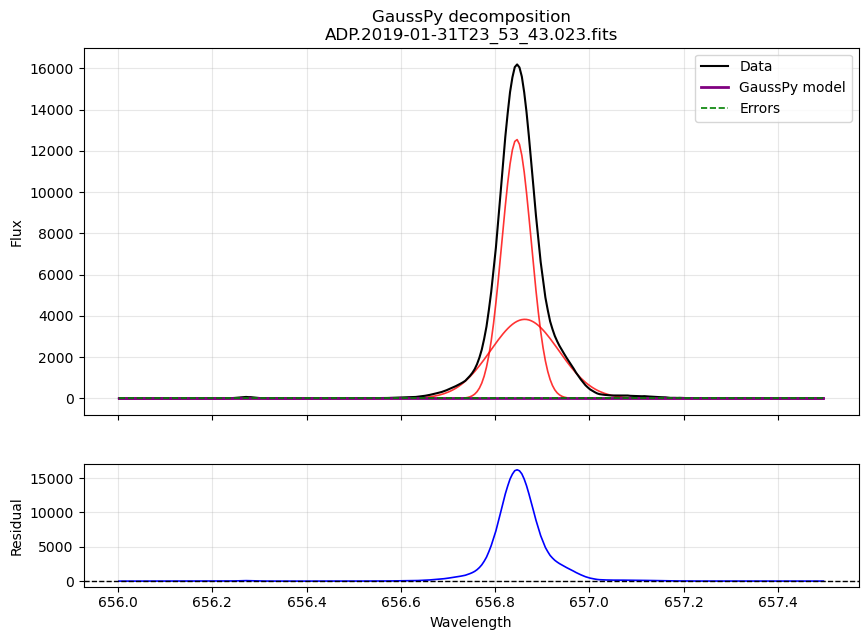

In [29]:
wave = np.asarray(gauss_input["metadata"][PLOT_INDEX]["wave"], dtype=float)

model = np.zeros(len(chan))
residuals = spectrum - model

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Top panel
for j in range(len(means_fit)):
    component = gaussian(amps_fit[j], fwhms_fit[j], means_fit[j])(chan)
    ax1.plot(wave, component, color="red", lw=1.2, alpha=0.8)

ax1.plot(wave, spectrum, label="Data", color="black", linewidth=1.5)
ax1.plot(wave, model, label="GaussPy model", color="purple", linewidth=2.0)
ax1.plot(wave, errors, label="Errors", color="green", linestyle="dashed", linewidth=1.2)

ax1.set_ylabel("Flux")
ax1.set_title(
    f"GaussPy decomposition\n"
    f"{gauss_input['metadata'][PLOT_INDEX]['filename']}"
)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Bottom panel
ax2.plot(wave, residuals, color="blue", linewidth=1.2)
ax2.axhline(0, color="black", linestyle="--", linewidth=1.0)
ax2.set_xlabel("Wavelength")
ax2.set_ylabel("Residual")
ax2.grid(True, alpha=0.3)

plt.show()

In [30]:
import numpy as np
import matplotlib.pyplot as plt


def gaussian_model(x, amp, fwhm, mean):
    """
    Gaussian parameterized by amplitude, FWHM, and mean.
    """
    return amp * np.exp(-4.0 * np.log(2.0) * (x - mean)**2 / fwhm**2)


def plot_gausspyplus_fit(
    gauss_input,
    data_decomp,
    plot_index=0,
    use_wavelength=True,
    show_errors=True,
    show_components=True,
    figsize=(10, 7),
    show=True,
):
    """
    Plot one GaussPy+ decomposition result for a validation spectrum.

    Parameters
    ----------
    gauss_input : dict
        Input dictionary used by GaussPy+. It must contain:
        'data_list', 'x_values', 'error', and 'metadata'.

    data_decomp : dict
        Output dictionary from GaussPy+ decomposition. It must contain:
        'means_fit', 'amplitudes_fit', 'fwhms_fit'.

    plot_index : int
        Index of the validation spectrum to plot.

    use_wavelength : bool
        If True, plot against wavelength using metadata['wave'].
        If False, plot against channel number.

    show_errors : bool
        If True, plot the scalar error level as a horizontal array.

    show_components : bool
        If True, plot individual Gaussian components.

    figsize : tuple
        Figure size.

    show : bool
        If True, display the figure.

    Returns
    -------
    fig, axes
        Matplotlib figure and axes.
    """

    # --------------------------
    # Extract input spectrum
    # --------------------------
    spectrum = np.asarray(gauss_input["data_list"][plot_index], dtype=float)

    # GaussPy+ input uses one common channel grid
    chan = np.asarray(gauss_input["x_values"], dtype=float)

    # GaussPy+ input uses scalar error per spectrum
    error_scalar = float(gauss_input["error"][plot_index])
    errors = error_scalar * np.ones_like(spectrum)

    metadata = gauss_input["metadata"][plot_index]

    # --------------------------
    # Safety check
    # --------------------------
    if len(chan) != len(spectrum):
        raise ValueError(
            f"Length mismatch: len(chan)={len(chan)}, "
            f"len(spectrum)={len(spectrum)}"
        )

    # --------------------------
    # Extract fitted parameters
    # --------------------------
    means_fit = np.asarray(data_decomp["means_fit"][plot_index], dtype=float)
    amps_fit = np.asarray(data_decomp["amplitudes_fit"][plot_index], dtype=float)
    fwhms_fit = np.asarray(data_decomp["fwhms_fit"][plot_index], dtype=float)

    # --------------------------
    # Build total model
    # --------------------------
    model = np.zeros_like(spectrum, dtype=float)
    components = []

    for amp, fwhm, mean in zip(amps_fit, fwhms_fit, means_fit):
        component = gaussian_model(chan, amp, fwhm, mean)
        components.append(component)
        model += component

    residuals = spectrum - model

    # --------------------------
    # Choose x-axis for plotting
    # --------------------------
    if use_wavelength:
        x_plot = np.asarray(metadata["wave"], dtype=float)

        if len(x_plot) != len(spectrum):
            raise ValueError(
                f"Length mismatch: len(wave)={len(x_plot)}, "
                f"len(spectrum)={len(spectrum)}"
            )

        x_label = "Wavelength"
    else:
        x_plot = chan
        x_label = "Channel"

    # --------------------------
    # Metadata for title
    # --------------------------
    filename = metadata.get("filename", "unknown filename")
    obj = metadata.get("object", "unknown object")

    rchi2 = data_decomp.get(
        "best_fit_rchi2",
        [None] * len(gauss_input["data_list"])
    )[plot_index]

    # --------------------------
    # Plot
    # --------------------------
    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )

    if show_components:
        for component in components:
            ax1.plot(
                x_plot,
                component,
                color="red",
                lw=1.2,
                alpha=0.8,
            )

    ax1.plot(
        x_plot,
        spectrum,
        label="Data",
        color="black",
        linewidth=1.5,
    )

    ax1.plot(
        x_plot,
        model,
        label="GaussPy+ model",
        color="purple",
        linewidth=2.0,
    )

    if show_errors:
        ax1.plot(
            x_plot,
            errors,
            label="Scalar error",
            color="green",
            linestyle="dashed",
            linewidth=1.2,
            alpha=0.8,
        )

    ax1.set_ylabel("Flux")
    ax1.set_title(
        f"GaussPy+ decomposition | index {plot_index}\n"
        f"{obj} | {filename}\n"
        f"ncomp = {len(means_fit)}, rchi2 = {rchi2}"
    )

    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(
        x_plot,
        residuals,
        color="blue",
        linewidth=1.2,
    )

    ax2.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.0,
    )

    ax2.set_xlabel(x_label)
    ax2.set_ylabel("Residual")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()

    if show:
        plt.show()

    return fig, (ax1, ax2)

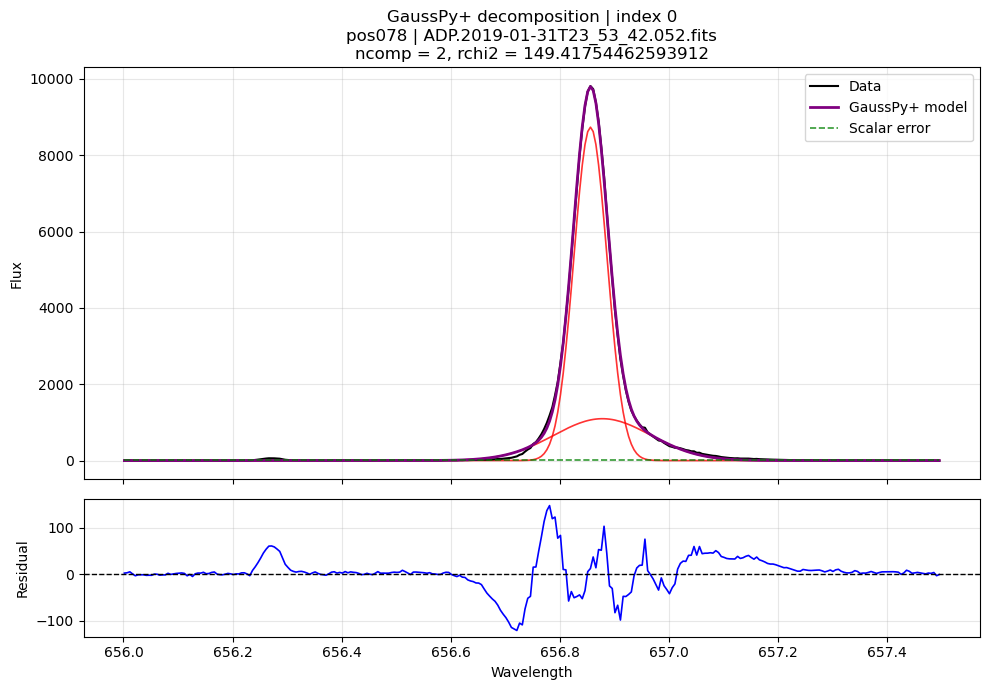

In [31]:
PLOT_INDEX = 0

fig, axes = plot_gausspyplus_fit(
    gauss_input,
    data_decomp_gplus,
    plot_index=PLOT_INDEX,
    use_wavelength=True,
    show_errors=True,
    show_components=True,
    figsize=(10, 7),
)

In [32]:
from pathlib import Path
import re
import matplotlib.pyplot as plt

# ============================================================
# Output folder for saved plots
# ============================================================

save_dir = Path("/Users/javier/FLAMES_30dor/gausspyp_v02.2/gausspy_validation/plots_validation")
save_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# Make sure we have the GaussPy+ decomposition result
# ============================================================

if data_decomp is not None:
    data_decomp_gplus = data_decomp
elif hasattr(decomp, "decomposition"):
    data_decomp_gplus = decomp.decomposition
else:
    raise ValueError("No GaussPy+ decomposition result found.")

# ============================================================
# Helper to make safe filenames
# ============================================================

def safe_string(text):
    """
    Convert text into a safe filename.
    """
    text = str(text)
    text = re.sub(r"[^\w\-_.]", "_", text)
    return text

# ============================================================
# Loop over all validation spectra and save plots
# ============================================================

n_spectra = len(gauss_input["data_list"])

print(f"Saving plots for {n_spectra} spectra...")
print(f"Output folder: {save_dir}")

plt.ioff()

for i in range(n_spectra):
    metadata = gauss_input["metadata"][i]

    filename = metadata.get("filename", f"spectrum_{i}")
    obj = metadata.get("object", f"obj_{i}")

    filename_safe = safe_string(filename)
    obj_safe = safe_string(obj)

    save_path = save_dir / f"{i:02d}_{obj_safe}_{filename_safe}.png"

    fig, axes = plot_gausspyplus_fit(
        gauss_input,
        data_decomp_gplus,
        plot_index=i,
        use_wavelength=True,
        show_errors=True,
        show_components=True,
        figsize=(10, 7),
        show=False,
    )

    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {save_path.name}")

plt.ion()

print("Done.")

Saving plots for 1382 spectra...
Output folder: /Users/javier/FLAMES_30dor/gausspyp_v02.2/gausspy_validation/plots_validation
Saved: 00_pos078_ADP.2019-01-31T23_53_42.052.fits.png
Saved: 01_pos011_ADP.2019-01-31T23_53_42.083.fits.png
Saved: 02_pos069_ADP.2019-01-31T23_53_42.122.fits.png
Saved: 03_pos037_ADP.2019-01-31T23_53_42.163.fits.png
Saved: 04_pos093_ADP.2019-01-31T23_53_42.236.fits.png
Saved: 05_pos039_ADP.2019-01-31T23_53_42.257.fits.png
Saved: 06_pos112_ADP.2019-01-31T23_53_42.309.fits.png
Saved: 07_pos100_ADP.2019-01-31T23_53_42.314.fits.png
Saved: 08_pos001_ADP.2019-01-31T23_53_42.332.fits.png
Saved: 09_pos016_ADP.2019-01-31T23_53_42.341.fits.png
Saved: 10_pos083_ADP.2019-01-31T23_53_42.368.fits.png
Saved: 11_pos008_ADP.2019-01-31T23_53_42.385.fits.png
Saved: 12_pos027_ADP.2019-01-31T23_53_42.431.fits.png
Saved: 13_pos090_ADP.2019-01-31T23_53_42.478.fits.png
Saved: 14_pos052_ADP.2019-01-31T23_53_42.557.fits.png
Saved: 15_pos023_ADP.2019-01-31T23_53_42.584.fits.png
Saved: 16_

In [33]:
out_dir

PosixPath('/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation')

In [34]:
from pathlib import Path
import pickle

#out_dir = Path("/Users/javier/FLAMES_30dor/gausspy_validation")

FILENAME_DATA = out_dir / "real_FLAMES_validation_input.pkl"
FILENAME_DATA_DECOMP = out_dir / "real_FLAMES_validation_decomposed.pkl"

print("Input file exists?")
print(FILENAME_DATA.exists(), FILENAME_DATA)

print("\nDecomposition file exists?")
print(FILENAME_DATA_DECOMP.exists(), FILENAME_DATA_DECOMP)

Input file exists?
True /Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/real_FLAMES_validation_input.pkl

Decomposition file exists?
True /Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/real_FLAMES_validation_decomposed.pkl


In [35]:
df_validation = df_flames
FILENAME_DF_VALIDATION = out_dir / "df_validation.pkl"

with open(FILENAME_DF_VALIDATION, "wb") as f:
    pickle.dump(df_validation, f)

print("Saved validation dataframe:")
print(FILENAME_DF_VALIDATION)
print("Exists?", FILENAME_DF_VALIDATION.exists())

Saved validation dataframe:
/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/df_validation.pkl
Exists? True


In [36]:
# ============================================================
# Save validation configuration
# ============================================================

training_config = {
    "phase": "two",
    "alpha1": 0.90,
    "alpha2": 1.72,
    "SNR_thresh": [10, 10],
    "input_file": str(FILENAME_DATA),
    "decomposition_file": str(FILENAME_DATA_DECOMP),
    "notes": "FLAMES 30 Dor validation sample using trained GaussPy two-phase parameters.",
}

FILENAME_CONFIG = out_dir / "validation_training_config.pkl"

with open(FILENAME_CONFIG, "wb") as f:
    pickle.dump(training_config, f)

print("Saved validation config:")
print(FILENAME_CONFIG)
print("Exists?", FILENAME_CONFIG.exists())

Saved validation config:
/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/validation_training_config.pkl
Exists? True


In [37]:
import numpy as np
import matplotlib.pyplot as plt


def gaussian_model(x, amp, fwhm, mean):
    """
    Gaussian parameterized by amplitude, FWHM, and mean.
    """
    return amp * np.exp(-4.0 * np.log(2.0) * (x - mean)**2 / fwhm**2)


def plot_spatial_spectra_grid_gausspyplus(
    gauss_input,
    data_decomp,
    *,
    use_wavelength=True,
    x_scale=0.0008,
    y_scale=0.0008,
    normalize=True,
    normalize_mode="local",
    percent_of_global_max=1.0,
    show_components=False,
    show_points=True,
    figsize=(9, 8),
):
    """
    Plot observed spectra and GaussPy+ models at their sky coordinates.

    Parameters
    ----------
    gauss_input : dict
        GaussPy+ input dictionary containing:
        data_list, x_values, error, metadata.

        Here x_values is one common channel array.

    data_decomp : dict
        GaussPy+ decomposition output containing:
        means_fit, amplitudes_fit, fwhms_fit.

    use_wavelength : bool, default=True
        If True, use wavelength to define the internal horizontal shape.
        If False, use channel number.

    x_scale : float, default=0.0008
        Horizontal size of each mini-spectrum in degrees.

    y_scale : float, default=0.0008
        Vertical size of each mini-spectrum in degrees.

    normalize : bool, default=True
        If True, normalize spectra before plotting.

    normalize_mode : {"local", "global", "percent"}, default="local"
        "local"   : each spectrum is normalized independently.
        "global"  : all spectra are normalized by the same global amplitude.
        "percent" : normalize by percent_of_global_max * global amplitude.

    percent_of_global_max : float, default=1.0
        Used only when normalize_mode="percent".

    show_components : bool, default=False
        If True, draw individual Gaussian components.

    show_points : bool, default=True
        If True, mark the actual RA/Dec coordinate of each spectrum.

    figsize : tuple, default=(9, 8)
        Figure size.

    Returns
    -------
    fig, ax : matplotlib figure and axis
    """

    if normalize_mode not in ["local", "global", "percent"]:
        raise ValueError("normalize_mode must be 'local', 'global', or 'percent'.")

    n_spectra = len(gauss_input["data_list"])

    # GaussPy+ input uses one common channel grid
    chan = np.asarray(gauss_input["x_values"], dtype=float)

    # ------------------------------------------------------------
    # Compute global amplitude scale if needed
    # ------------------------------------------------------------
    if normalize and normalize_mode in ["global", "percent"]:
        all_amplitudes = []

        for i in range(n_spectra):
            flux_i = np.asarray(gauss_input["data_list"][i], dtype=float)
            amp_i = np.nanmax(flux_i) - np.nanmedian(flux_i)

            if np.isfinite(amp_i):
                all_amplitudes.append(amp_i)

        if len(all_amplitudes) == 0:
            global_amp = np.nan
        else:
            global_amp = np.nanmax(all_amplitudes)
    else:
        global_amp = None

    # ------------------------------------------------------------
    # Create figure
    # ------------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)

    # ------------------------------------------------------------
    # Loop over spectra
    # ------------------------------------------------------------
    for i in range(n_spectra):

        meta = gauss_input["metadata"][i]

        ra = meta["ra_deg"]
        dec = meta["dec_deg"]

        flux = np.asarray(gauss_input["data_list"][i], dtype=float)

        if len(flux) != len(chan):
            raise ValueError(
                f"Length mismatch at index {i}: "
                f"len(flux)={len(flux)}, len(chan)={len(chan)}"
            )

        if use_wavelength:
            x_native = np.asarray(meta["wave"], dtype=float)

            if len(x_native) != len(flux):
                raise ValueError(
                    f"Length mismatch at index {i}: "
                    f"len(wave)={len(x_native)}, len(flux)={len(flux)}"
                )
        else:
            x_native = chan

        means = np.asarray(data_decomp["means_fit"][i], dtype=float)
        amps = np.asarray(data_decomp["amplitudes_fit"][i], dtype=float)
        fwhms = np.asarray(data_decomp["fwhms_fit"][i], dtype=float)

        # --------------------------------------------------------
        # Build GaussPy+ model
        # --------------------------------------------------------
        model = np.zeros_like(flux, dtype=float)
        components = []

        for amp, fwhm, mean in zip(amps, fwhms, means):
            comp = gaussian_model(chan, amp, fwhm, mean)
            components.append(comp)
            model += comp

        # --------------------------------------------------------
        # Normalize x coordinate of each mini-spectrum
        # --------------------------------------------------------
        x_range = np.nanmax(x_native) - np.nanmin(x_native)

        if not np.isfinite(x_range) or x_range == 0:
            continue

        x_norm = (x_native - np.nanmin(x_native)) / x_range
        x_norm = x_norm - 0.5

        # --------------------------------------------------------
        # Normalize y coordinate of each mini-spectrum
        # --------------------------------------------------------
        if normalize:

            if normalize_mode == "local":
                fmin = np.nanmin(flux)
                fmax = np.nanmax(flux)
                scale = fmax - fmin
                offset = fmin

                if np.isfinite(scale) and scale > 0:
                    flux_plot = (flux - offset) / scale
                    model_plot = (model - offset) / scale
                    comp_plots = [(c - offset) / scale for c in components]
                else:
                    flux_plot = np.zeros_like(flux)
                    model_plot = np.zeros_like(model)
                    comp_plots = [np.zeros_like(c) for c in components]

            elif normalize_mode == "global":
                scale = global_amp

                if np.isfinite(scale) and scale > 0:
                    flux_plot = flux / scale
                    model_plot = model / scale
                    comp_plots = [c / scale for c in components]
                else:
                    flux_plot = np.zeros_like(flux)
                    model_plot = np.zeros_like(model)
                    comp_plots = [np.zeros_like(c) for c in components]

            elif normalize_mode == "percent":
                scale = percent_of_global_max * global_amp

                if np.isfinite(scale) and scale > 0:
                    flux_plot = flux / scale
                    model_plot = model / scale
                    comp_plots = [c / scale for c in components]
                else:
                    flux_plot = np.zeros_like(flux)
                    model_plot = np.zeros_like(model)
                    comp_plots = [np.zeros_like(c) for c in components]

            # Center each mini-spectrum vertically around its coordinate
            flux_plot = flux_plot - np.nanmedian(flux_plot)
            model_plot = model_plot - np.nanmedian(model_plot)
            comp_plots = [c - np.nanmedian(c) for c in comp_plots]

        else:
            flux_plot = flux
            model_plot = model
            comp_plots = components

        # --------------------------------------------------------
        # Convert mini-spectrum to sky-coordinate offsets
        # --------------------------------------------------------
        x_plot = ra + x_scale * x_norm
        y_data = dec + y_scale * flux_plot
        y_model = dec + y_scale * model_plot

        ax.plot(
            x_plot,
            y_data,
            color="black",
            lw=0.8,
            alpha=0.8,
        )

        ax.plot(
            x_plot,
            y_model,
            color="red",
            lw=1.0,
            alpha=0.9,
        )

        if show_components:
            for comp_plot in comp_plots:
                y_comp = dec + y_scale * comp_plot

                ax.plot(
                    x_plot,
                    y_comp,
                    color="blue",
                    lw=0.6,
                    alpha=0.5,
                )

        if show_points:
            ax.scatter(
                ra,
                dec,
                s=8,
                color="gray",
                alpha=0.6,
                zorder=3,
            )

    ax.set_xlabel("RA [deg]")
    ax.set_ylabel("Dec [deg]")

    ax.set_title(
        "Spatial grid of FLAMES spectra with GaussPy+ fits\n"
        f"normalize_mode = {normalize_mode}"
    )

    ax.invert_xaxis()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    return fig, ax

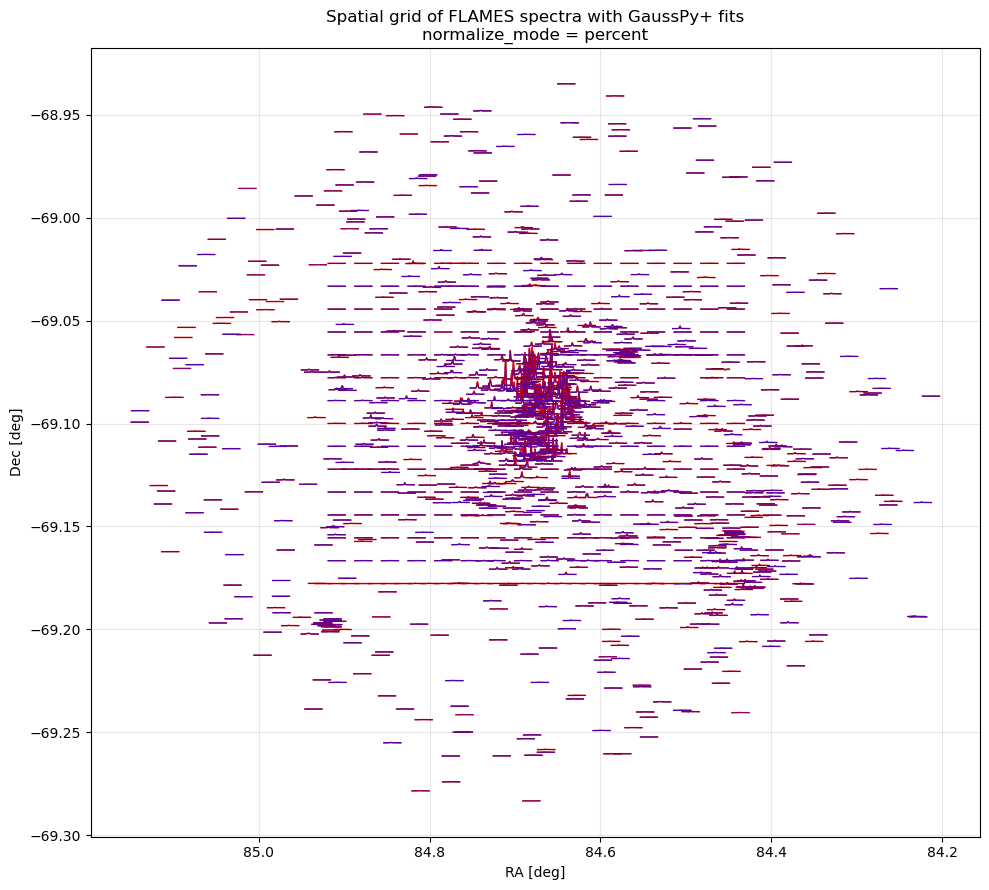

In [38]:
fig, ax = plot_spatial_spectra_grid_gausspyplus(
    gauss_input,
    data_decomp_gplus,
    use_wavelength=True,
    x_scale=0.02,
    y_scale=0.005,
    normalize=True,
    normalize_mode="percent",
    percent_of_global_max=0.25,
    show_components=True,
    show_points=False,
    figsize=(10, 9),
)
fig.savefig("spatial_spectra_grid_gausspyplus.png", dpi=200, bbox_inches="tight")
plt.show()